# 1 — Linear correlation analysis: do any light-curve statistics track age?

Asks one question carefully: **does any measured parameter correlate with cluster age once the
observational and galaxy-level nuisances are accounted for?**

Three facts about this dataset shape everything below.

1. **Rows are not independent.** The pipeline emits one row per sector combination, and
   combinations of the same cluster share sectors — up to 409 rows for one LMC cluster. Naive
   row-level statistics would overstate significance by roughly `sqrt(rows per cluster)`. The
   unit of analysis here is the **cluster**; row-level results appear only as a cross-check
   with a mixed model.
2. **Galaxy is confounded with age.** LMC clusters in this sample are young (mean log age 7.87,
   none above 8.8) while the MW spans 6.4–10.1. Distance, metallicity and crowding also differ
   by galaxy. So a feature that merely tracks brightness will correlate with age *through*
   origin. This is the main trap, and §4–§5 are built to avoid it.
3. **Brightness and cadence drive the variability statistics mechanically.** A fainter cluster
   has a higher photometric floor, which inflates excess variance and shifts the periodogram
   continuum. Those are nuisances, not results.

**What is deliberately not controlled for:** the GP quality flags. They are outcomes of the fit
and are themselves age-related (capped fraction has ρ = −0.18 with age), so conditioning on them
would open a collider path and can manufacture correlations. They are used to describe the
sample and in sensitivity checks only.

In [54]:
%load_ext autoreload
%autoreload 2

import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

sys.path.insert(0, os.path.abspath('.'))
import analysis_utils as A

GT = '/astro/users/cgwill/TESS_Cluster_Age_ML/GenerateTable_CGW/data'
# Prefer the full <=3-sector table once it exists; fall back to the 1250-row sample.
CANDIDATES = [
    f'{GT}/cluster_table_Sep23_all_combos_le3sectors.pkl',
    f'{GT}/cluster_table_Sep21_3sectorcombos_real_nofallback.pkl',
]
TABLE = next(p for p in CANDIDATES if os.path.exists(p))
print('using', os.path.basename(TABLE))

pd.set_option('display.width', 220)
plt.rcParams.update({'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb',
                     'axes.grid': True, 'grid.color': '#e6e5e0', 'axes.axisbelow': True,
                     'axes.spines.top': False, 'axes.spines.right': False, 'legend.frameon': False})

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
using cluster_table_Sep23_all_combos_le3sectors.pkl


In [55]:
rows = A.load_rows(TABLE)
meta = A.cluster_metadata()                 # RA/DEC/radius from the ELK headers, + galactic b
clusters = A.cluster_table(rows, meta=meta)

FEATURES  = [c for c, _, _ in A.feature_columns(rows)]
NUISANCES = [n for n, _, _ in A.NUISANCE_SPEC if n in clusters.columns]
print(f'{len(clusters)} clusters, {len(FEATURES)} features, {len(NUISANCES)} nuisances')
print('nuisances:', NUISANCES)
clusters[['name', 'origin', 'age', 'n_rows']].head()

17233 rows, 348 clusters from cluster_table_Sep23_all_combos_le3sectors.pkl
rows per cluster: median 3, max 409
348 clusters, 23 features, 9 nuisances
nuisances: ['origin', 'log_cadence', 'n_sectors', 'log_n_points', 'log_med_err_frac', 'log_med_flux', 'cluster_radius', 'dec', 'gal_b']


,name,origin,age,n_rows
0,ASCC 116,MW,7.95,6
1,ASCC 57,MW,9.26,4
2,ASCC 8,MW,7.77,2
3,ASCC 81,MW,8.75,2
4,ASCC 9,MW,7.00,1


## 2 · The sample, and how age is distributed

Before any correlation: how much age range is there *within* each galaxy? If a galaxy spans
almost no age range, it cannot contribute to a within-galaxy test, and any signal from it is
really a between-galaxy comparison.

,clusters,rows,age_min,age_med,age_max,age_iqr
origin,,,,,,
LMC,118,16666,6.80,7.90,8.80,0.57
MW,124,367,6.40,8.53,10.10,1.05
SMC,106,200,7.07,8.20,10.02,0.68


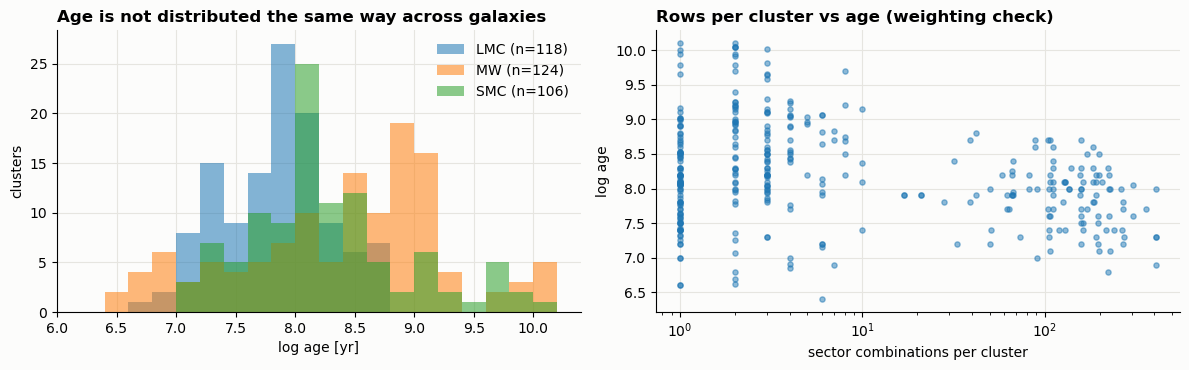

CONCLUSION —
  MW spans 3.7 dex of age, LMC only 2.0 dex, and the
  galaxies sit at different median ages (LMC 7.9, MW 8.5, SMC 8.2).
  Galaxy is therefore entangled with age: any feature that differs between galaxies can
  inherit an age correlation. Every result below is repeated with origin controlled.


In [56]:
desc = clusters.groupby('origin').agg(clusters=('age', 'size'), rows=('n_rows', 'sum'),
                                     age_min=('age', 'min'), age_med=('age', 'median'),
                                     age_max=('age', 'max'), age_iqr=('age', lambda s: s.quantile(.75) - s.quantile(.25)))
display(desc.round(2))

fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
for o, g in clusters.groupby('origin'):
    axs[0].hist(g.age, bins=np.arange(6.2, 10.4, 0.2), alpha=.55, label=f'{o} (n={len(g)})')
axs[0].set(xlabel='log age [yr]', ylabel='clusters'); axs[0].legend()
axs[0].set_title('Age is not distributed the same way across galaxies', loc='left', fontweight='bold')
axs[1].scatter(clusters.n_rows, clusters.age, s=14, alpha=.5)
axs[1].set(xscale='log', xlabel='sector combinations per cluster', ylabel='log age')
axs[1].set_title('Rows per cluster vs age (weighting check)', loc='left', fontweight='bold')
plt.tight_layout(); plt.show()

span = desc.age_max - desc.age_min
widest, narrowest = span.idxmax(), span.idxmin()
print('CONCLUSION —')
print(f'  {widest} spans {span[widest]:.1f} dex of age, {narrowest} only {span[narrowest]:.1f} dex, and the')
print(f'  galaxies sit at different median ages ({", ".join(f"{o} {a:.1f}" for o, a in desc.age_med.items())}).')
print('  Galaxy is therefore entangled with age: any feature that differs between galaxies can')
print('  inherit an age correlation. Every result below is repeated with origin controlled.')


## 3 · The confounding map

Which nuisances are themselves related to age? Anything strongly related here is a route by
which a feature can inherit a spurious age correlation.

In [57]:
rowsn = []
for n in NUISANCES:
    if n == 'origin':
        groups = [g.age.values for _, g in clusters.groupby('origin')]
        H, p = stats.kruskal(*groups)
        eta2 = (H - len(groups) + 1) / (len(clusters) - len(groups))     # epsilon-squared
        rowsn.append(dict(nuisance='origin', stat=f'Kruskal H={H:.1f}', effect=eta2, p=p))
    else:
        rho, p = stats.spearmanr(clusters[n], clusters.age, nan_policy='omit')
        rowsn.append(dict(nuisance=n, stat='Spearman', effect=rho, p=p))
conf = pd.DataFrame(rowsn).sort_values('effect', key=abs, ascending=False)
conf['flag'] = np.where(conf.p < 0.01, 'CONFOUNDER', '')
display(conf.round(4))
print('\nRead this first: any feature correlated with a flagged nuisance can pick up an age')
print('correlation without any astrophysical connection.')

strong = conf[(conf.p < 0.01) & (conf.effect.abs() > 0.15)]
print('CONCLUSION —')
if len(strong):
    print(f'  {len(strong)} nuisance(s) track age themselves: '
          + ', '.join(f'{r.nuisance} ({r.effect:+.2f})' for _, r in strong.iterrows()) + '.')
    print('  Those are the routes by which a feature can look age-related without being so,')
    print('  and they are what the partial analysis removes.')
else:
    print('  No nuisance tracks age strongly, so confounding is unlikely to drive the results.')


,nuisance,stat,effect,p,flag
2,n_sectors,Spearman,-0.3119,0.0000,CONFOUNDER
6,cluster_radius,Spearman,0.2853,0.0000,CONFOUNDER
3,log_n_points,Spearman,-0.2441,0.0000,CONFOUNDER
4,log_med_err_frac,Spearman,-0.1804,0.0007,CONFOUNDER
8,gal_b,Spearman,0.1425,0.0078,CONFOUNDER
0,origin,Kruskal H=43.1,0.1191,0.0000,CONFOUNDER
7,dec,Spearman,0.0948,0.0775,
1,log_cadence,Spearman,-0.0566,0.2920,
5,log_med_flux,Spearman,-0.0011,0.9841,



Read this first: any feature correlated with a flagged nuisance can pick up an age
correlation without any astrophysical connection.
CONCLUSION —
  4 nuisance(s) track age themselves: n_sectors (-0.31), cluster_radius (+0.29), log_n_points (-0.24), log_med_err_frac (-0.18).
  Those are the routes by which a feature can look age-related without being so,
  and they are what the partial analysis removes.


## 4 · Marginal correlations (the naive answer)

Spearman per feature against age, at cluster level, with:
* **BH-FDR** across features, because ~23 tests at p<0.05 would give one false positive by chance;
* **bootstrap CIs resampling clusters**, which is the honest uncertainty given the sample size.

These numbers are the *upper bound* on what we can claim — they ignore confounding entirely.

In [58]:
res = []
for f in FEATURES:
    rho, p, (lo, hi) = A.spearman_ci(clusters[f], clusters.age, n_boot=1000, seed=0)
    n = int((clusters[f].notna() & clusters.age.notna()).sum())
    res.append(dict(feature=f, n=n, rho=rho, ci_lo=lo, ci_hi=hi, p=p))
marg = pd.DataFrame(res)
marg['p_fdr'] = A.bh_fdr(marg.p.fillna(1))
marg = marg.sort_values('rho', key=abs, ascending=False)
display(marg.round(3))

sig = marg[marg.p_fdr < 0.05]
print('CONCLUSION —')
print(f'  {len(sig)} of {len(marg)} features correlate with age before any control (FDR < 0.05); '
      f'strongest |rho| = {marg.rho.abs().max():.2f}.')
print('  These are upper bounds: galaxy and observing setup are still folded in.')


,feature,n,rho,ci_lo,ci_hi,p,p_fdr
3,intrinsic_rms,341,-0.372,-0.465,-0.282,0.000,0.000
1,intrinsic_std,341,-0.371,-0.465,-0.282,0.000,0.000
0,excess_var,341,-0.371,-0.465,-0.282,0.000,0.000
2,sigma_mad,348,-0.339,-0.439,-0.241,0.000,0.000
19,gp_sigma_max,311,-0.301,-0.401,-0.194,0.000,0.000
16,gp_rn_rms_band,348,-0.217,-0.309,-0.126,0.000,0.000
15,gp_rn_log10_S0,348,-0.216,-0.307,-0.126,0.000,0.000
18,gp_n_components_filtered,348,-0.163,-0.254,-0.063,0.002,0.007
20,gp_period_strongest,311,-0.152,-0.261,-0.044,0.007,0.015
10,LSP_peak_snr_at_diff,348,-0.146,-0.244,-0.048,0.006,0.015


CONCLUSION —
  12 of 23 features correlate with age before any control (FDR < 0.05); strongest |rho| = 0.37.
  These are upper bounds: galaxy and observing setup are still folded in.


## 5 · Within galaxy, and partial correlations

Two ways to strip the confounding, which fail differently — agreement between them is the
evidence that matters.

* **Within-origin:** compute the correlation separately per galaxy. No cross-galaxy comparison
  can leak in, but each subsample is smaller and the LMC spans little age range.
* **Partial (rank) correlation:** residualise both age-rank and feature-rank on the full nuisance
  design (galaxy dummies, cadence, sectors, length, noise floor, brightness, radius, dec,
  galactic latitude), then correlate. Uses all clusters, but assumes the nuisance relationships
  are roughly linear in rank space.
* **Stratified permutation test:** shuffles age *within* galaxy, so the null preserves the
  galaxy–age association and only destroys the feature–age link.

In [59]:
per_origin = []
for f in FEATURES:
    row = {'feature': f}
    for o, g in clusters.groupby('origin'):
        rho, p = stats.spearmanr(g[f], g.age, nan_policy='omit')
        row[f'rho_{o}'] = rho
        row[f'n_{o}'] = int(g[f].notna().sum())
    row['rho_partial'], row['p_partial'], row['n_partial'] = A.partial_spearman(
        clusters, f, 'age', NUISANCES)
    _, row['p_perm'] = A.stratified_permutation_p(clusters, f, 'age', 'origin', n_perm=1000)
    per_origin.append(row)
part = pd.DataFrame(per_origin)
part['p_partial_fdr'] = A.bh_fdr(part.p_partial.fillna(1))
part['p_perm_fdr'] = A.bh_fdr(part.p_perm.fillna(1))
out = marg[['feature', 'rho', 'p_fdr']].merge(part, on='feature').sort_values('rho_partial', key=abs, ascending=False)
display(out.round(3))

agree = out[(out.p_partial_fdr < 0.05) & (out.p_perm_fdr < 0.05)]
print('CONCLUSION —')
print(f'  {len(agree)} features pass BOTH the partial correlation and the within-galaxy permutation')
print(f'  test at FDR < 0.05: ' + (', '.join(agree.feature.head(6)) if len(agree) else 'none') + '.')
print('  The two tests fail differently, so agreement between them is the evidence that counts.')


,feature,rho,p_fdr,rho_LMC,n_LMC,rho_MW,n_MW,rho_SMC,n_SMC,rho_partial,p_partial,n_partial,p_perm,p_partial_fdr,p_perm_fdr
0,intrinsic_rms,-0.372,0.000,-0.251,118,-0.297,124,-0.216,99,-0.256,0.000,341,0.001,0.000,0.003
1,intrinsic_std,-0.371,0.000,-0.252,118,-0.297,124,-0.217,99,-0.256,0.000,341,0.001,0.000,0.003
2,excess_var,-0.371,0.000,-0.252,118,-0.297,124,-0.217,99,-0.256,0.000,341,0.001,0.000,0.003
3,sigma_mad,-0.339,0.000,0.054,118,-0.305,124,-0.278,106,-0.229,0.000,348,0.001,0.000,0.003
13,rn_alpha,-0.099,0.107,-0.588,118,-0.069,124,-0.208,106,-0.223,0.000,348,0.624,0.000,0.971
10,vn_ratio_gap_aware,-0.145,0.015,-0.469,118,-0.148,124,-0.237,106,-0.213,0.000,348,0.054,0.000,0.113
15,stetson_j_gap_aware,-0.048,0.539,-0.487,118,-0.177,124,-0.206,106,-0.198,0.000,348,0.990,0.001,1.000
4,gp_sigma_max,-0.301,0.000,-0.197,114,-0.214,114,-0.051,83,-0.185,0.001,311,0.001,0.003,0.003
7,gp_n_components_filtered,-0.163,0.007,-0.352,118,-0.155,124,-0.105,106,-0.179,0.001,348,0.001,0.003,0.003
11,LSP_peak_snr_rn,-0.133,0.025,-0.246,118,-0.116,124,-0.220,106,-0.172,0.002,348,0.023,0.004,0.053


CONCLUSION —
  9 features pass BOTH the partial correlation and the within-galaxy permutation
  test at FDR < 0.05: intrinsic_rms, intrinsic_std, excess_var, sigma_mad, gp_sigma_max, gp_n_components_filtered.
  The two tests fail differently, so agreement between them is the evidence that counts.


## 5b · Results at a glance

Four figures that answer, in order: *what survives*, *what was killed and by what*, *why*, and
*is it the same in every galaxy*.

Watch for two opposite effects. A correlation can **shrink** under control (it was the galaxy or
the brightness all along), or it can **grow** — suppression, where a nuisance was masking a real
relation. `rn_alpha` is the clearest example here: essentially flat in the raw data, but a clear
correlation once galaxy and brightness are removed. Both are marked in the figures.

In [60]:
# Partial correlations with bootstrap CIs, and the confounding attribution
att = A.attribution_table(clusters, FEATURES, 'age', NUISANCES)
ci_rows = []
for f in FEATURES:
    rho_p, p_p, (lo, hi), n = A.partial_spearman_ci(clusters, f, 'age', NUISANCES, n_boot=300, seed=0)
    ci_rows.append(dict(feature=f, rho_partial=rho_p, p_partial=p_p, lo=lo, hi=hi, n=n))
ci = pd.DataFrame(ci_rows)
ci['p_partial_fdr'] = A.bh_fdr(ci.p_partial.fillna(1))
summary = (marg[['feature', 'rho', 'ci_lo', 'ci_hi', 'p_fdr']]
           .rename(columns={'rho': 'rho_marginal', 'ci_lo': 'marg_lo', 'ci_hi': 'marg_hi',
                            'p_fdr': 'p_marginal_fdr'})
           .merge(ci, on='feature')
           .merge(att[['feature', 'dominant_nuisance', 'shrinkage', 'verdict']], on='feature'))
summary['survives'] = (summary.p_partial_fdr < 0.05) & (summary.rho_partial.abs() > 0.12)
summary = summary.sort_values('rho_partial', key=abs, ascending=False)
display(summary.round(3))

print('CONCLUSION —')
print(f'  {int(summary.survives.sum())} of {len(summary)} features survive: partial |rho| > 0.12 at FDR < 0.05.')
flip = summary[(np.sign(summary.rho_marginal) != np.sign(summary.rho_partial))
               & (summary.rho_marginal.abs() > 0.12) & (summary.rho_partial.abs() > 0.12)]
if len(flip):
    print('  Sign flipped under control despite both being non-trivial (treat as unreliable): '
          + ', '.join(flip.feature) + '.')
else:
    print('  No feature reverses sign under control at a magnitude worth taking seriously.')


,feature,rho_marginal,marg_lo,marg_hi,p_marginal_fdr,rho_partial,p_partial,lo,hi,n,p_partial_fdr,dominant_nuisance,shrinkage,verdict,survives
0,intrinsic_rms,-0.372,-0.465,-0.282,0.000,-0.256,0.000,-0.361,-0.140,341,0.000,origin,0.310,weakened by origin,True
1,intrinsic_std,-0.371,-0.465,-0.282,0.000,-0.256,0.000,-0.361,-0.140,341,0.000,origin,0.312,weakened by origin,True
2,excess_var,-0.371,-0.465,-0.282,0.000,-0.256,0.000,-0.361,-0.140,341,0.000,origin,0.312,weakened by origin,True
3,sigma_mad,-0.339,-0.439,-0.241,0.000,-0.229,0.000,-0.335,-0.106,348,0.000,origin,0.325,weakened by origin,True
13,rn_alpha,-0.099,-0.199,0.011,0.107,-0.223,0.000,-0.325,-0.130,348,0.000,log_cadence,-1.253,revealed by control,True
10,vn_ratio_gap_aware,-0.145,-0.237,-0.044,0.015,-0.213,0.000,-0.307,-0.113,348,0.000,log_med_flux,-0.469,revealed by control,True
15,stetson_j_gap_aware,-0.048,-0.150,0.059,0.539,-0.198,0.000,-0.293,-0.088,348,0.001,log_cadence,-3.141,revealed by control,True
4,gp_sigma_max,-0.301,-0.401,-0.194,0.000,-0.185,0.001,-0.285,-0.064,311,0.003,cluster_radius,0.385,weakened by cluster_radius,True
7,gp_n_components_filtered,-0.163,-0.254,-0.063,0.007,-0.179,0.001,-0.272,-0.071,348,0.003,gal_b,-0.098,survives,True
11,LSP_peak_snr_rn,-0.133,-0.227,-0.033,0.025,-0.172,0.002,-0.264,-0.068,348,0.004,gal_b,-0.292,survives,True


CONCLUSION —
  15 of 23 features survive: partial |rho| > 0.12 at FDR < 0.05.
  No feature reverses sign under control at a magnitude worth taking seriously.


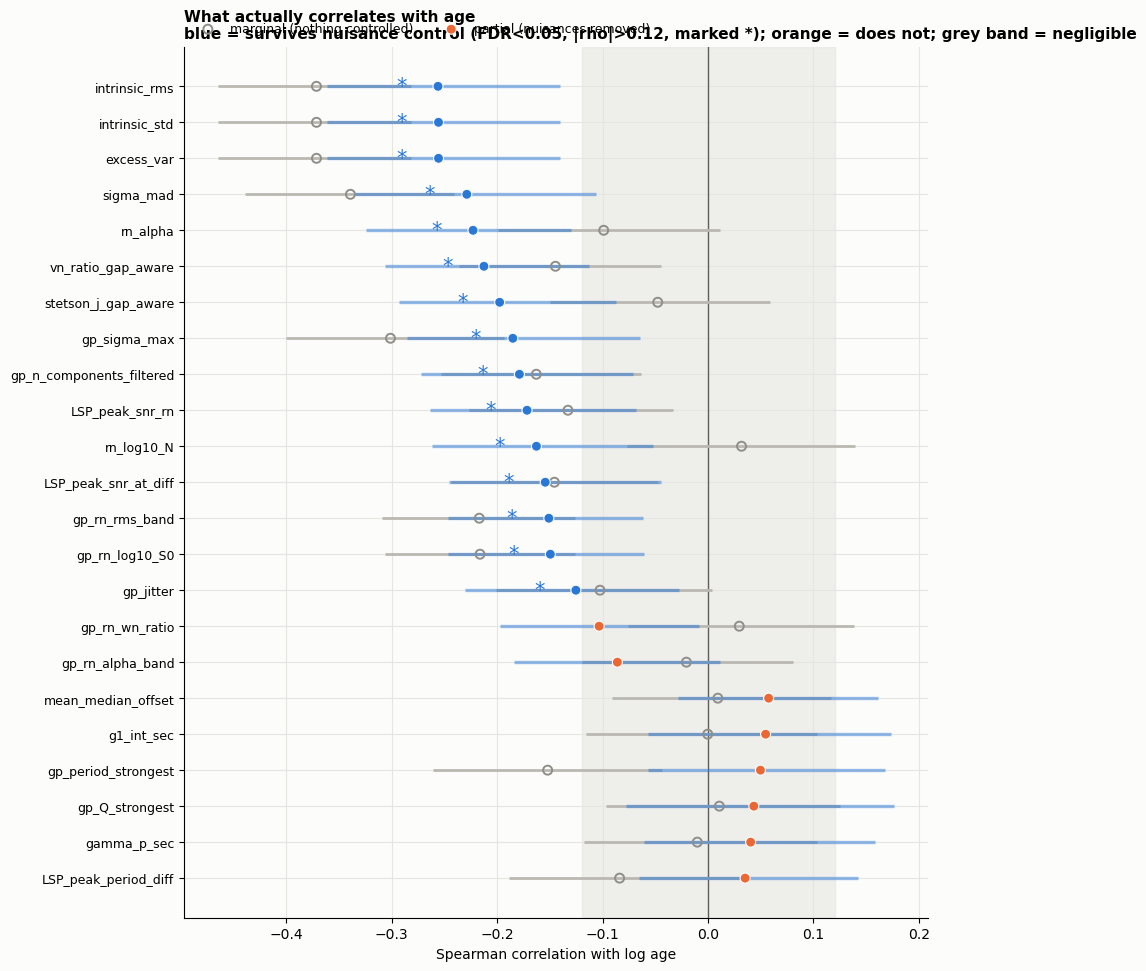

CONCLUSION —
  15 of 23 features keep a correlation with age after nuisance control.
  Strongest: intrinsic_rms (-0.26), intrinsic_std (-0.26), excess_var (-0.26).


In [61]:
# FIGURE 1 - what survives: marginal vs partial with CIs, sorted by partial strength
d = summary.iloc[::-1]
y = np.arange(len(d))
fig, ax = plt.subplots(figsize=(9.5, 0.34 * len(d) + 2))
ax.axvline(0, color='#5f5e5a', lw=1)
ax.axvspan(-0.12, 0.12, color='#e6e5e0', alpha=.6, zorder=0)      # "too weak to matter" band
ax.hlines(y, d.marg_lo, d.marg_hi, color='#b9b8b1', lw=2)
ax.scatter(d.rho_marginal, y, s=42, facecolors='none', edgecolors='#8f8e88', lw=1.4,
           label='marginal (nothing controlled)', zorder=3)
ax.hlines(y, d.lo, d.hi, color='#2a78d6', lw=2.4, alpha=.5)
ax.scatter(d.rho_partial, y, s=52, color=np.where(d.survives, '#2a78d6', '#eb6834'),
           edgecolors='#fcfcfb', lw=.8, zorder=4, label='partial (nuisances removed)')
for yi, (_, r) in zip(y, d.iterrows()):
    if r.survives:
        ax.text(r.rho_partial + (0.03 if r.rho_partial > 0 else -0.03), yi, '*',
                va='center', ha='left' if r.rho_partial > 0 else 'right', fontsize=15, color='#2a78d6')
ax.set_yticks(y, d.feature, fontsize=9)
ax.set(xlabel='Spearman correlation with log age', ylabel='')
ax.set_title('What actually correlates with age\n'
             'blue = survives nuisance control (FDR<0.05, |rho|>0.12, marked *); '
             'orange = does not; grey band = negligible',
             loc='left', fontweight='bold', fontsize=11)
ax.legend(fontsize=9, loc='lower left', bbox_to_anchor=(0.0, 1.0), ncol=2)
plt.tight_layout(); plt.show()

surv = summary[summary.survives]
print('CONCLUSION —')
print(f'  {len(surv)} of {len(summary)} features keep a correlation with age after nuisance control.')
if len(surv):
    top = surv.head(3)
    print('  Strongest: ' + ', '.join(f'{r.feature} ({r.rho_partial:+.2f})' for _, r in top.iterrows()) + '.')
    shrunk = summary[(summary.rho_marginal.abs() > 0.2) & (~summary.survives)]
    if len(shrunk):
        print('  Lost to nuisances despite a strong raw correlation: '
              + ', '.join(shrunk.feature.head(3)) + '.')
else:
    print('  Nothing survives — the raw correlations were all explainable by galaxy or observing setup.')


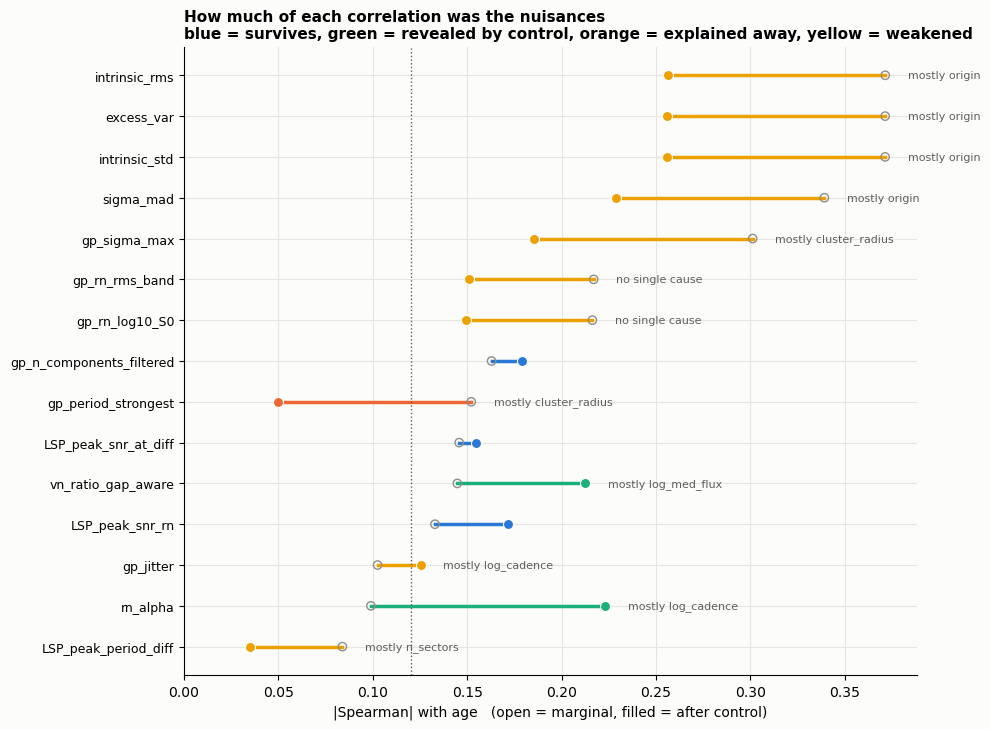

CONCLUSION —
  Of the raw correlations: 3 largely intact, 4 only appear after control, 8 shrink or vanish, 8 were never there.
  Biggest loss: gp_period_strongest shed 67% of its correlation (-0.15 -> +0.05), mostly cluster_radius.
  Hidden by nuisances until controlled (suppression): rn_alpha, vn_ratio_gap_aware, stetson_j_gap_aware, rn_log10_N.


In [62]:
# FIGURE 2 - attrition: how much each feature loses when nuisances are removed, and to what
d = summary[summary.rho_marginal.abs() > 0.08].copy().sort_values('rho_marginal', key=abs)
fig, ax = plt.subplots(figsize=(10, 0.36 * len(d) + 2))
y = np.arange(len(d))
colour = {'survives': '#2a78d6'}
def _vcol(v):
    if v.startswith('survives'):        return '#2a78d6'    # blue: real
    if v.startswith('revealed'):        return '#1baf7a'    # green: a nuisance was hiding it
    if v.startswith('explained'):       return '#eb6834'    # orange: it was the nuisance
    return '#eda100'                                        # yellow: partly the nuisance
cols = [_vcol(v) for v in d.verdict]
for yi, (_, r), c in zip(y, d.iterrows(), cols):
    ax.plot([abs(r.rho_marginal), abs(r.rho_partial)], [yi, yi], color=c, lw=2.5, zorder=2)
    ax.scatter(abs(r.rho_marginal), yi, s=36, facecolors='none', edgecolors='#8f8e88', zorder=3)
    ax.scatter(abs(r.rho_partial), yi, s=52, color=c, edgecolors='#fcfcfb', lw=.8, zorder=4)
    if not r.verdict.startswith('survives') and r.dominant_nuisance:
        ax.text(max(abs(r.rho_marginal), abs(r.rho_partial)) + 0.012, yi,
                f'mostly {r.dominant_nuisance}' if 'jointly' not in r.verdict else 'no single cause',
                va='center', fontsize=8, color='#5f5e5a')
ax.axvline(0.12, color='#5f5e5a', ls=':', lw=1)
ax.set_yticks(y, d.feature, fontsize=9)
ax.set(xlabel='|Spearman| with age   (open = marginal, filled = after control)', xlim=(0, None))
ax.set_title('How much of each correlation was the nuisances\n'
             'blue = survives, green = revealed by control, orange = explained away, yellow = weakened',
             loc='left', fontweight='bold', fontsize=11)
plt.tight_layout(); plt.show()

v = summary.verdict.value_counts()
print('CONCLUSION —')
print(f'  Of the raw correlations: {int(v.get("survives", 0))} largely intact, '
      f'{int(v.get("revealed by control", 0))} only appear after control, '
      f'{int(sum(n for k, n in v.items() if "by" in k and "revealed" not in k))} shrink or vanish, '
      f'{int(v.get("weak", 0))} were never there.')
real = summary[summary.rho_marginal.abs() > 0.15]      # only meaningful where there was something to lose
worst = real.loc[real.shrinkage.idxmax()] if len(real) and real.shrinkage.notna().any() else None
if worst is not None:
    print(f'  Biggest loss: {worst.feature} shed {100*worst.shrinkage:.0f}% of its correlation '
          f'({worst.rho_marginal:+.2f} -> {worst.rho_partial:+.2f}), mostly {worst.dominant_nuisance}.')
rev = summary[summary.verdict.str.startswith("revealed")]
if len(rev):
    print('  Hidden by nuisances until controlled (suppression): ' + ', '.join(rev.feature) + '.')


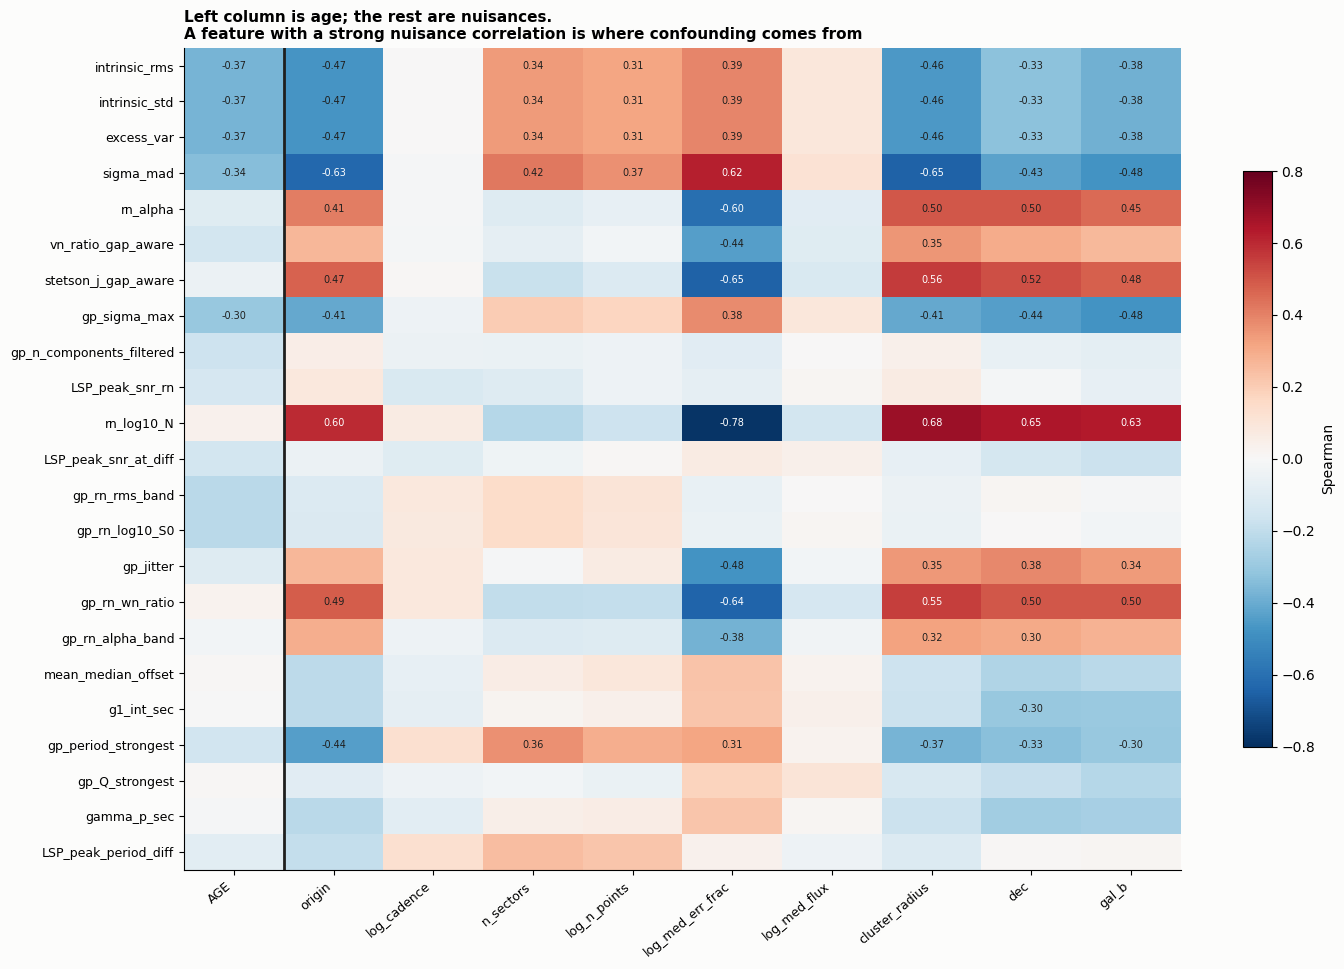

CONCLUSION —
  The most entangled nuisance is log_med_err_frac; its strongest tie is to rn_log10_N (|rho| = 0.78).
  5 of 23 features are correlated above 0.5 with some nuisance, which is why marginal correlations cannot be taken at face value.


In [63]:
# FIGURE 3 - why: what each feature is correlated with, besides age
rho_mat = pd.DataFrame(index=FEATURES, columns=['AGE'] + NUISANCES, dtype=float)
for f in FEATURES:
    rho_mat.loc[f, 'AGE'] = stats.spearmanr(clusters[f], clusters.age, nan_policy='omit')[0]
    for n in NUISANCES:
        if n == 'origin':
            # rank-biserial style: correlation with the galaxy's median age, as a stand-in
            codes = clusters.groupby('origin').age.transform('median')
            rho_mat.loc[f, n] = stats.spearmanr(clusters[f], codes, nan_policy='omit')[0]
        else:
            rho_mat.loc[f, n] = stats.spearmanr(clusters[f], clusters[n], nan_policy='omit')[0]
order = summary.set_index('feature').loc[FEATURES].rho_partial.abs().sort_values(ascending=False).index
rho_mat = rho_mat.loc[order]
fig, ax = plt.subplots(figsize=(1.05 * rho_mat.shape[1] + 4, 0.33 * len(rho_mat) + 2.2))
im = ax.imshow(rho_mat.values.astype(float), cmap='RdBu_r', vmin=-.8, vmax=.8, aspect='auto')
ax.set_xticks(range(rho_mat.shape[1]), rho_mat.columns, rotation=40, ha='right', fontsize=9)
ax.set_yticks(range(len(rho_mat)), rho_mat.index, fontsize=9)
for i in range(rho_mat.shape[0]):
    for j in range(rho_mat.shape[1]):
        v = rho_mat.values[i, j]
        if np.isfinite(v) and abs(v) > 0.3:
            ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=7,
                    color='white' if abs(v) > 0.55 else '#1f1f1e')
ax.axvline(0.5, color='#1f1f1e', lw=2)
fig.colorbar(im, ax=ax, label='Spearman', shrink=.7)
ax.grid(False)
ax.set_title('Left column is age; the rest are nuisances.\n'
             'A feature with a strong nuisance correlation is where confounding comes from',
             loc='left', fontweight='bold', fontsize=11)
plt.tight_layout(); plt.show()

nu_only = rho_mat.drop(columns=['AGE']).abs()
worst_nu = nu_only.max().idxmax()
pair = nu_only.stack().idxmax()
print('CONCLUSION —')
print(f'  The most entangled nuisance is {worst_nu}; its strongest tie is to {pair[0]} '
      f'(|rho| = {nu_only.loc[pair]:.2f}).')
ent = (nu_only > 0.5).any(axis=1)
print(f'  {int(ent.sum())} of {len(nu_only)} features are correlated above 0.5 with some nuisance, '
      'which is why marginal correlations cannot be taken at face value.')


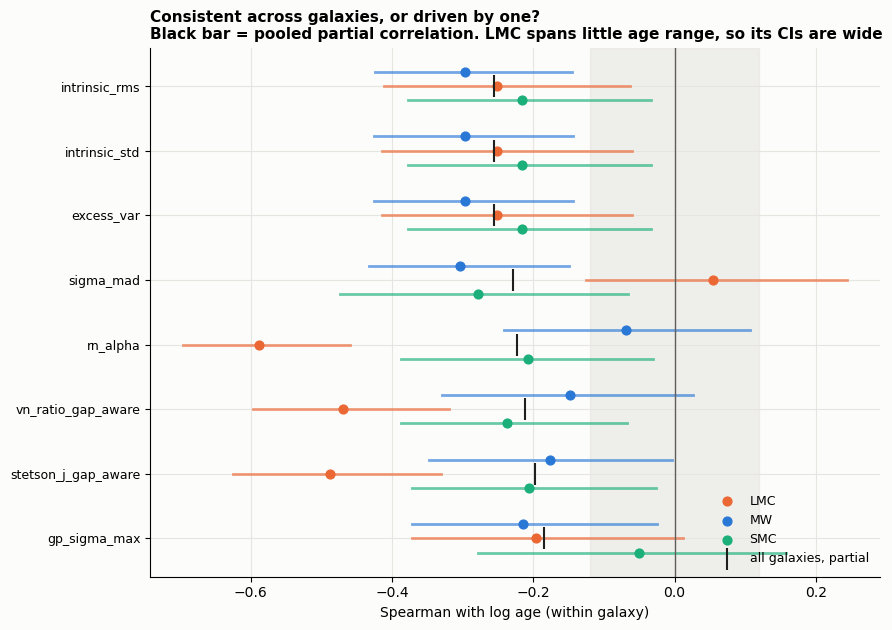

CONCLUSION —
  intrinsic_rms            LMC -0.25 MW -0.30 SMC -0.22   -> consistent across galaxies (spread 0.08)
  intrinsic_std            LMC -0.25 MW -0.30 SMC -0.22   -> consistent across galaxies (spread 0.08)
  excess_var               LMC -0.25 MW -0.30 SMC -0.22   -> consistent across galaxies (spread 0.08)
  sigma_mad                LMC +0.05 MW -0.30 SMC -0.28   -> INCONSISTENT — sign differs between galaxies (spread 0.36)
  rn_alpha                 LMC -0.59 MW -0.07 SMC -0.21   -> same sign but dominated by LMC (others much weaker) (spread 0.52)
  vn_ratio_gap_aware       LMC -0.47 MW -0.15 SMC -0.24   -> same sign but dominated by LMC (others much weaker) (spread 0.32)
  A feature driven by one galaxy only is the weakest kind of evidence here; the MW is the
  only subsample with a wide age range, so an MW-only signal rests on ~124 clusters.


In [64]:
# FIGURE 4 - is it the same story in each galaxy?
show = summary.head(8).feature.tolist()
fig, ax = plt.subplots(figsize=(9, 0.55 * len(show) + 2))
offs = {'MW': .22, 'LMC': 0.0, 'SMC': -.22}
cols = {'MW': '#2a78d6', 'LMC': '#eb6834', 'SMC': '#1baf7a'}
for k, f in enumerate(show[::-1]):
    for o, g in clusters.groupby('origin'):
        if g[f].notna().sum() < 25:
            continue
        rho, p, (lo, hi) = A.spearman_ci(g[f], g.age, n_boot=400, seed=1)
        ax.plot([lo, hi], [k + offs[o]] * 2, color=cols[o], lw=2, alpha=.65)
        ax.scatter(rho, k + offs[o], s=40, color=cols[o], zorder=3,
                   label=o if k == 0 else None)
    rp = summary.set_index('feature').loc[f]
    ax.scatter(rp.rho_partial, k, marker='|', s=260, color='#1f1f1e', zorder=4,
               label='all galaxies, partial' if k == 0 else None)
ax.axvline(0, color='#5f5e5a', lw=1)
ax.axvspan(-0.12, 0.12, color='#e6e5e0', alpha=.6, zorder=0)
ax.set_yticks(range(len(show)), show[::-1], fontsize=9)
ax.set(xlabel='Spearman with log age (within galaxy)')
ax.set_title('Consistent across galaxies, or driven by one?\n'
             'Black bar = pooled partial correlation. LMC spans little age range, so its CIs are wide',
             loc='left', fontweight='bold', fontsize=11)
ax.legend(fontsize=9, loc='lower right')
plt.tight_layout(); plt.show()

print('CONCLUSION —')
for f in show[:6]:
    rr = {}
    for o, g in clusters.groupby('origin'):
        if g[f].notna().sum() >= 25:
            rr[o] = stats.spearmanr(g[f], g.age, nan_policy='omit')[0]
    if not rr:
        continue
    signs = set(np.sign(list(rr.values())))
    spread = max(rr.values()) - min(rr.values())
    if len(signs) > 1:
        tag = 'INCONSISTENT — sign differs between galaxies'
    elif spread > 0.25:
        dom = max(rr, key=lambda o: abs(rr[o]))
        tag = f'same sign but dominated by {dom} (others much weaker)'
    else:
        tag = 'consistent across galaxies'
    print(f'  {f:<24} ' + ' '.join(f'{o} {v:+.2f}' for o, v in rr.items())
          + f'   -> {tag} (spread {spread:.2f})')
print('  A feature driven by one galaxy only is the weakest kind of evidence here; the MW is the')
print('  only subsample with a wide age range, so an MW-only signal rests on ~124 clusters.')


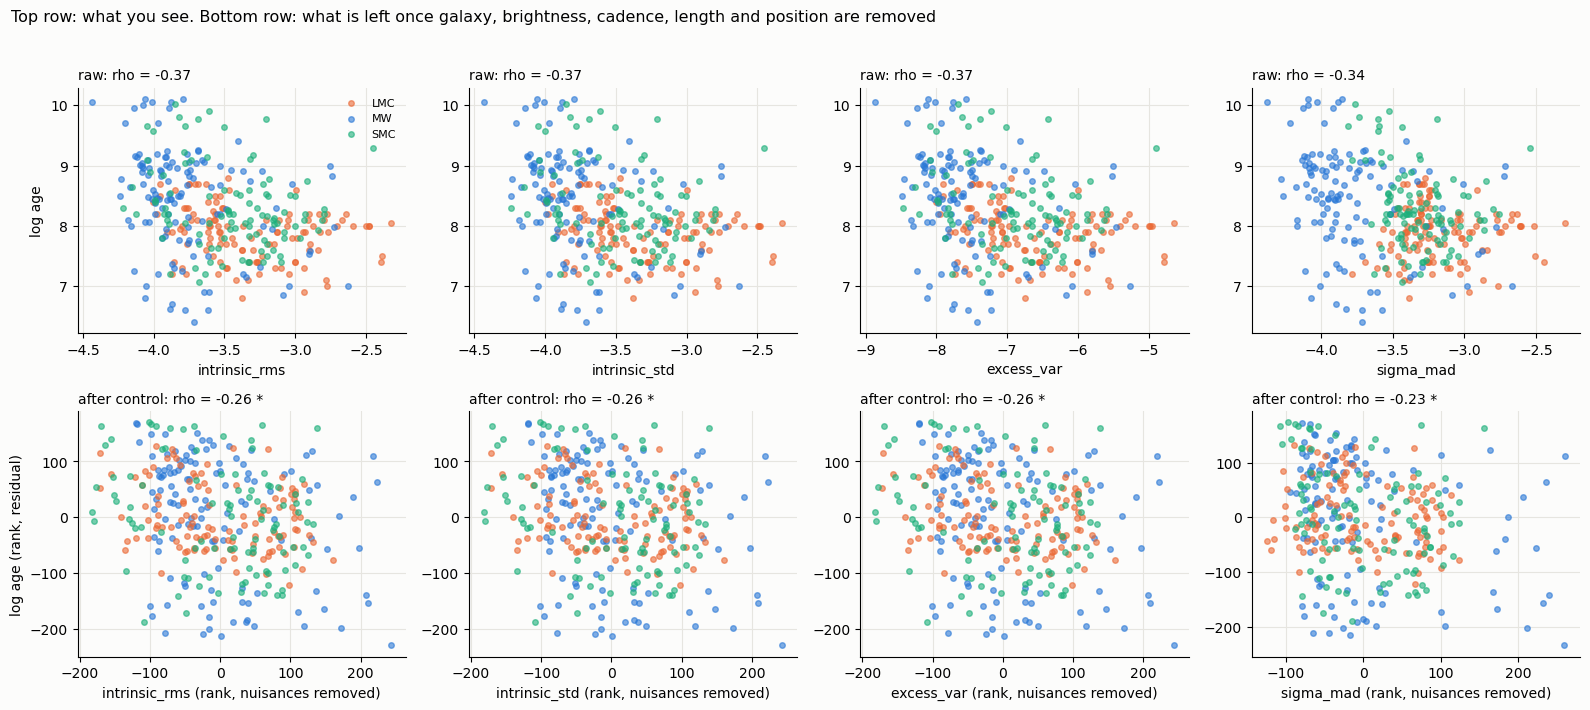

CONCLUSION —
  intrinsic_rms            raw -0.37 -> controlled -0.26 (keeps 69% of it), CI [-0.36, -0.14]
  intrinsic_std            raw -0.37 -> controlled -0.26 (keeps 69% of it), CI [-0.36, -0.14]
  excess_var               raw -0.37 -> controlled -0.26 (keeps 69% of it), CI [-0.36, -0.14]
  sigma_mad                raw -0.34 -> controlled -0.23 (keeps 67% of it), CI [-0.33, -0.11]
  The bottom row is the relation the data actually support: rank of the feature against
  rank of age, with galaxy, brightness, cadence, length and position projected out.


In [65]:
# FIGURE 5 - the surviving features, raw and after removing the nuisances
survivors = summary[summary.survives].feature.tolist()[:4]
if not survivors:
    survivors = summary.head(2).feature.tolist()
    print('nothing cleared the bar; showing the two strongest anyway')
X = A.design_matrix(clusters, NUISANCES)
fig, axs = plt.subplots(2, len(survivors), figsize=(4.0 * len(survivors), 7.2), squeeze=False)
for j, f in enumerate(survivors):
    keep = list(dict.fromkeys([f, 'age', 'origin'] + NUISANCES))   # origin is also a nuisance
    sub = clusters[keep].dropna(subset=[f, 'age'])
    for o, g in sub.groupby('origin'):
        axs[0][j].scatter(g[f], g.age, s=16, alpha=.6, color=cols.get(o, '#8f8e88'), label=o)
    r = summary.set_index('feature').loc[f]
    axs[0][j].set(xlabel=f, ylabel='log age' if j == 0 else '')
    axs[0][j].set_title(f'raw: rho = {r.rho_marginal:+.2f}', loc='left', fontsize=10)

    Xs = A.design_matrix(sub, NUISANCES)
    rx = A._residualise(sub[f].rank(), Xs); ry = A._residualise(sub['age'].rank(), Xs)
    for o in sub.origin.unique():
        m = (sub.origin.values == o)
        axs[1][j].scatter(rx[m], ry[m], s=16, alpha=.6, color=cols.get(o, '#8f8e88'))
    axs[1][j].set(xlabel=f'{f} (rank, nuisances removed)', ylabel='log age (rank, residual)' if j == 0 else '')
    axs[1][j].set_title(f'after control: rho = {r.rho_partial:+.2f}'
                        f'{" *" if r.survives else ""}', loc='left', fontsize=10)
axs[0][0].legend(fontsize=8)
fig.suptitle('Top row: what you see. Bottom row: what is left once galaxy, brightness, cadence, '
             'length and position are removed', x=0.01, ha='left', fontsize=11.5)
plt.tight_layout(rect=[0, 0, 1, 0.96]); plt.show()

print('CONCLUSION —')
for f in survivors:
    r = summary.set_index('feature').loc[f]
    kept = 100 * abs(r.rho_partial) / abs(r.rho_marginal) if abs(r.rho_marginal) > 1e-9 else np.inf
    word = 'keeps' if kept <= 120 else 'gains'
    print(f'  {f:<24} raw {r.rho_marginal:+.2f} -> controlled {r.rho_partial:+.2f} '
          f'({word} {min(kept,999):.0f}% of it), CI [{r.lo:+.2f}, {r.hi:+.2f}]')
print('  The bottom row is the relation the data actually support: rank of the feature against')
print('  rank of age, with galaxy, brightness, cadence, length and position projected out.')


In [66]:
print('VERDICT')
print('=' * 70)
for _, r in summary.iterrows():
    if abs(r.rho_marginal) < 0.08 and abs(r.rho_partial) < 0.08:
        continue
    mark = 'SURVIVES ' if r.survives else '         '
    print(f'{mark}{r.feature:<26} marginal {r.rho_marginal:+.2f} -> partial {r.rho_partial:+.2f}'
          f'  [{r.lo:+.2f}, {r.hi:+.2f}]   {r.verdict}')
print('=' * 70)
print(f'{int(summary.survives.sum())} of {len(summary)} features survive nuisance control.')

VERDICT
SURVIVES intrinsic_rms              marginal -0.37 -> partial -0.26  [-0.36, -0.14]   weakened by origin
SURVIVES intrinsic_std              marginal -0.37 -> partial -0.26  [-0.36, -0.14]   weakened by origin
SURVIVES excess_var                 marginal -0.37 -> partial -0.26  [-0.36, -0.14]   weakened by origin
SURVIVES sigma_mad                  marginal -0.34 -> partial -0.23  [-0.33, -0.11]   weakened by origin
SURVIVES rn_alpha                   marginal -0.10 -> partial -0.22  [-0.32, -0.13]   revealed by control
SURVIVES vn_ratio_gap_aware         marginal -0.14 -> partial -0.21  [-0.31, -0.11]   revealed by control
SURVIVES stetson_j_gap_aware        marginal -0.05 -> partial -0.20  [-0.29, -0.09]   revealed by control
SURVIVES gp_sigma_max               marginal -0.30 -> partial -0.19  [-0.29, -0.06]   weakened by cluster_radius
SURVIVES gp_n_components_filtered   marginal -0.16 -> partial -0.18  [-0.27, -0.07]   survives
SURVIVES LSP_peak_snr_rn            marginal -

## 5c · Feature families: 23 columns are not 23 measurements

Several columns describe the same physical quantity. `excess_var`, `intrinsic_std`,
`intrinsic_rms` and `sigma_mad` are four views of one scatter; `vn_ratio`, `stetson_j`,
`rn_alpha` and `rn_log10_N` all measure *how red* the noise is. Testing them separately
triple-counts one result and drags every genuinely independent feature through a harsher FDR
correction than it deserves.

Families are found by clustering features on `1 − |Spearman|` (average linkage, cut at
|ρ| > 0.8). **Age is never used**, so the grouping cannot be tuned to the answer. Each family
gets two summaries:

* a **representative** — the member with the highest measurement reliability, i.e. the one whose
  value agrees best across a cluster's own sector combinations (again, age-free);
* an **index** — the mean of z-scored ranks of its members, signs aligned internally, which is
  less noisy than any single member.

The FDR correction then runs over **families**, which is the honest number of tests.

In [67]:
reliability = A.feature_reliability(rows)          # ICC across each cluster's sector combos
clusters_f, families, FAM_COLS = A.build_family_table(clusters, FEATURES, threshold=0.8,
                                                      reliability=reliability)
fam_summary = (families.groupby('family')
               .agg(n_members=('n_members', 'first'), mean_abs_rho=('mean_abs_rho', 'first'),
                    members=('feature', lambda s: ', '.join(s)))
               .sort_values('n_members', ascending=False))
fam_summary['representative_reliability'] = reliability.reindex(fam_summary.index).round(2)
display(fam_summary)
print(f'{len(fam_summary)} families from {len(FEATURES)} features '
      f'-> FDR over {len(fam_summary)} tests instead of {len(FEATURES)}')

print('CONCLUSION —')
print(f'  {len(fam_summary)} families; the largest has {fam_summary.n_members.max()} members.')
print(f'  Representatives are the most repeatable member of each family (reliability shown), '
      f'chosen without reference to age.')


,n_members,mean_abs_rho,members,representative_reliability
family,,,,
sigma_mad,5,0.926290,"excess_var, intrinsic_std, sigma_mad, intrinsi...",0.96
stetson_j_gap_aware,4,0.848396,"vn_ratio_gap_aware, stetson_j_gap_aware, rn_al...",0.96
LSP_peak_snr_rn,2,0.939502,"LSP_peak_snr_at_diff, LSP_peak_snr_rn",0.81
gp_rn_rms_band,2,0.997075,"gp_rn_log10_S0, gp_rn_rms_band",0.52
gp_rn_wn_ratio,2,0.828947,"gp_rn_alpha_band, gp_rn_wn_ratio",0.57
mean_median_offset,2,0.957879,"gamma_p_sec, mean_median_offset",0.76
LSP_peak_period_diff,1,1.000000,LSP_peak_period_diff,0.67
g1_int_sec,1,1.000000,g1_int_sec,0.56
gp_Q_strongest,1,1.000000,gp_Q_strongest,0.30


12 families from 23 features -> FDR over 12 tests instead of 23
CONCLUSION —
  12 families; the largest has 5 members.
  Representatives are the most repeatable member of each family (reliability shown), chosen without reference to age.


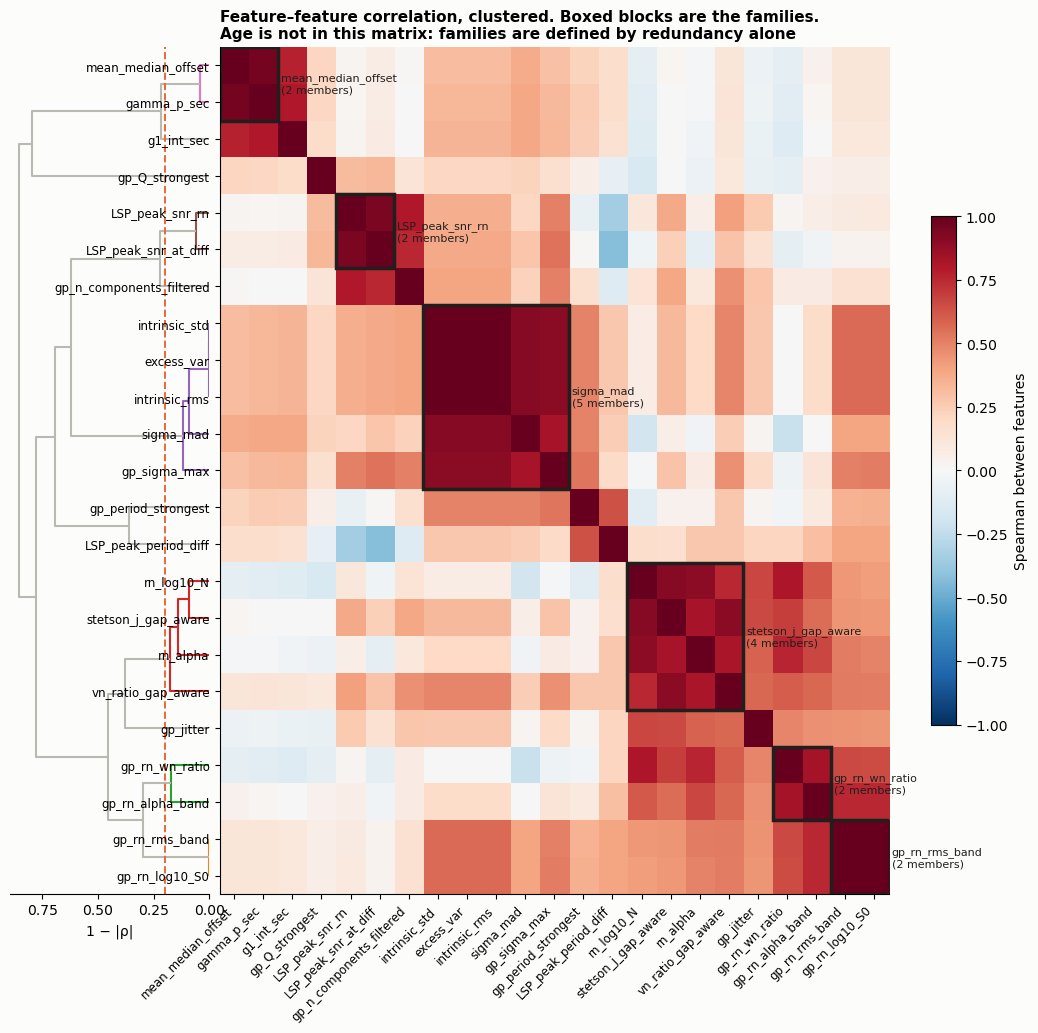

CONCLUSION —
  12 families from 23 features. The largest holds 5 members at mean |rho| 0.93: excess_var, intrinsic_std, sigma_mad, intrinsic_rms, gp_sigma_max.
  Effectively duplicate columns (|rho| > 0.99): excess_var = intrinsic_std; excess_var = intrinsic_rms; intrinsic_rms = intrinsic_std; gp_rn_log10_S0 = gp_rn_rms_band — one of each pair is redundant.
  Testing these separately would count one measurement many times and penalise every
  other feature through the multiple-testing correction.


In [68]:
# FIGURE - the correlation structure that defines the families (age plays no part)
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform

R = clusters[FEATURES].corr(method='spearman')
D = (1 - R.abs()).to_numpy(copy=True); np.fill_diagonal(D, 0.0)
D = np.nan_to_num(D, nan=1.0); D = 0.5 * (D + D.T)
Z = linkage(squareform(D, checks=False), 'average')

fig = plt.figure(figsize=(13.5, 11))
gs = fig.add_gridspec(1, 2, width_ratios=[1, 4.2], wspace=0.02)
axd = fig.add_subplot(gs[0]); axh = fig.add_subplot(gs[1])
dn = dendrogram(Z, labels=FEATURES, orientation='left', ax=axd,
                color_threshold=0.2, above_threshold_color='#b9b8b1')
axd.axvline(0.2, color='#eb6834', ls='--', lw=1.4)     # the |rho| = 0.8 cut
axd.set(xlabel='1 − |ρ|'); axd.grid(False)
axd.set_yticks([]); axd.spines[['top', 'right', 'left']].set_visible(False)

order = dn['ivl'][::-1]                                 # dendrogram leaf order, top to bottom
M = R.loc[order, order]
im = axh.imshow(M.values.astype(float), cmap='RdBu_r', vmin=-1, vmax=1, aspect='auto')
axh.set_xticks(range(len(order)), order, rotation=45, ha='right', fontsize=8.5)
axh.set_yticks(range(len(order)), order, fontsize=8.5)
axh.grid(False)

fam_of = families.set_index('feature').family
start = 0
for i in range(1, len(order) + 1):
    if i == len(order) or fam_of[order[i]] != fam_of[order[start]]:
        if i - start > 1:                                # outline multi-member families only
            axh.add_patch(plt.Rectangle((start - .5, start - .5), i - start, i - start,
                                        fill=False, edgecolor='#1f1f1e', lw=2.5))
            axh.text(i - .4, (start + i - 1) / 2, f'{fam_of[order[start]]}\n({i - start} members)',
                     va='center', fontsize=8, color='#1f1f1e')
        start = i
fig.colorbar(im, ax=axh, shrink=.6, label='Spearman between features')
axh.set_title('Feature–feature correlation, clustered. Boxed blocks are the families.\n'
              'Age is not in this matrix: families are defined by redundancy alone',
              loc='left', fontweight='bold', fontsize=11)
plt.show()

big = fam_summary.iloc[0]
dupes = [(a, b) for a in FEATURES for b in FEATURES if a < b and abs(R.loc[a, b]) > 0.99]
print('CONCLUSION —')
print(f'  {len(fam_summary)} families from {len(FEATURES)} features. The largest holds {big.n_members} '
      f'members at mean |rho| {big.mean_abs_rho:.2f}: {big.members}.')
if dupes:
    print('  Effectively duplicate columns (|rho| > 0.99): '
          + '; '.join(f'{a} = {b}' for a, b in dupes) + ' — one of each pair is redundant.')
print('  Testing these separately would count one measurement many times and penalise every')
print('  other feature through the multiple-testing correction.')


In [69]:
# Family-level correlations with age, FDR over families
fam_res = []
for col in FAM_COLS:
    rep = col.replace('FAM_', '')
    members = families[families.family == rep].feature.tolist()
    m_rho, _, (mlo, mhi) = A.spearman_ci(clusters_f[col], clusters_f.age, n_boot=500, seed=0)
    p_rho, p_p, (plo, phi), n = A.partial_spearman_ci(clusters_f, col, 'age', NUISANCES,
                                                      n_boot=300, seed=0)
    rep_rho, rep_p, _ = A.partial_spearman(clusters, rep, 'age', NUISANCES)
    fam_res.append(dict(family=rep, n_members=len(members), index_marginal=m_rho,
                        index_partial=p_rho, index_lo=plo, index_hi=phi, p=p_p,
                        representative_partial=rep_rho, members=', '.join(members)))
fam_tab = pd.DataFrame(fam_res)
fam_tab['p_fdr'] = A.bh_fdr(fam_tab.p.fillna(1))
fam_tab['survives'] = (fam_tab.p_fdr < 0.05) & (fam_tab.index_partial.abs() > 0.12)
fam_tab = fam_tab.sort_values('index_partial', key=abs, ascending=False)
display(fam_tab.drop(columns='members').round(3))
print('index vs representative: the two should agree; large gaps mean the family is not coherent')

gap = (fam_tab.index_partial - fam_tab.representative_partial).abs()
print('CONCLUSION —')
print(f'  {int(fam_tab.survives.sum())} of {len(fam_tab)} families survive nuisance control.')
print(f'  Index and representative agree to within {gap.max():.02f} at worst, so the composites are')
print('  faithful summaries rather than artefacts of averaging.')


,family,n_members,index_marginal,index_partial,index_lo,index_hi,p,representative_partial,p_fdr,survives
10,sigma_mad,5,-0.374,-0.263,-0.366,-0.148,0.000,-0.229,0.000,True
11,stetson_j_gap_aware,4,-0.062,-0.206,-0.303,-0.113,0.000,-0.198,0.001,True
5,gp_n_components_filtered,1,-0.163,-0.179,-0.272,-0.071,0.001,-0.179,0.004,True
1,LSP_peak_snr_rn,2,-0.144,-0.167,-0.253,-0.064,0.002,-0.172,0.006,True
7,gp_rn_rms_band,2,-0.217,-0.150,-0.247,-0.063,0.006,-0.151,0.014,True
4,gp_jitter,1,-0.102,-0.125,-0.230,-0.028,0.021,-0.125,0.042,True
8,gp_rn_wn_ratio,2,0.006,-0.099,-0.191,-0.005,0.069,-0.103,0.118,False
2,g1_int_sec,1,-0.000,0.055,-0.057,0.173,0.317,0.055,0.475,False
6,gp_period_strongest,1,-0.152,0.050,-0.057,0.168,0.390,0.050,0.477,False
9,mean_median_offset,2,-0.004,0.046,-0.045,0.159,0.397,0.058,0.477,False


index vs representative: the two should agree; large gaps mean the family is not coherent
CONCLUSION —
  6 of 12 families survive nuisance control.
  Index and representative agree to within 0.03 at worst, so the composites are
  faithful summaries rather than artefacts of averaging.


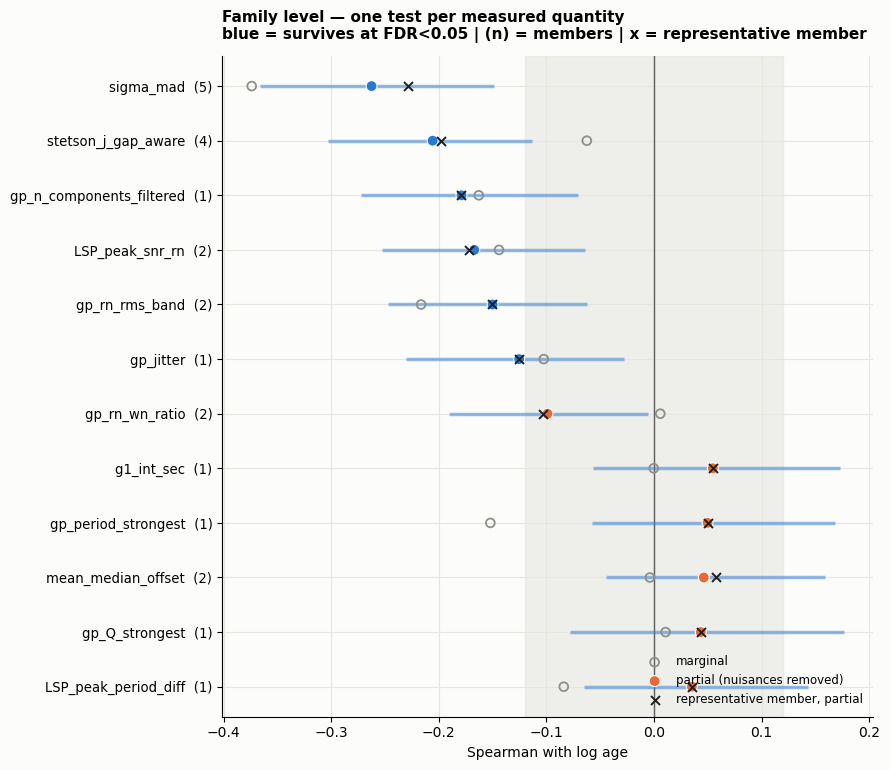

6 of 12 families survive; compare 15 of 23 at feature level (feature level over-counts redundant columns)
CONCLUSION —
  6 of 12 families survive, against 15 of 23 at feature level — the difference is redundancy, not evidence.
  sigma_mad              partial -0.26 [-0.37, -0.15], FDR p = 1e-05, covers: excess_var, intrinsic_std, sigma_mad, intrinsic_rms, gp_sigma_max
  stetson_j_gap_aware    partial -0.21 [-0.30, -0.11], FDR p = 0.0008, covers: vn_ratio_gap_aware, stetson_j_gap_aware, rn_alpha, rn_log10_N
  gp_n_components_filtered partial -0.18 [-0.27, -0.07], FDR p = 0.004, covers: gp_n_components_filtered
  LSP_peak_snr_rn        partial -0.17 [-0.25, -0.06], FDR p = 0.006, covers: LSP_peak_snr_at_diff, LSP_peak_snr_rn
  gp_rn_rms_band         partial -0.15 [-0.25, -0.06], FDR p = 0.01, covers: gp_rn_log10_S0, gp_rn_rms_band
  gp_jitter              partial -0.13 [-0.23, -0.03], FDR p = 0.04, covers: gp_jitter


In [70]:
# Family-level version of the headline figure
d = fam_tab.iloc[::-1]
y = np.arange(len(d))
fig, ax = plt.subplots(figsize=(9, 0.45 * len(d) + 2.4))
ax.axvline(0, color='#5f5e5a', lw=1)
ax.axvspan(-0.12, 0.12, color='#e6e5e0', alpha=.6, zorder=0)
ax.hlines(y, d.index_lo, d.index_hi, color='#2a78d6', lw=2.5, alpha=.5)
ax.scatter(d.index_marginal, y, s=40, facecolors='none', edgecolors='#8f8e88', lw=1.3,
           label='marginal', zorder=3)
ax.scatter(d.index_partial, y, s=62, color=np.where(d.survives, '#2a78d6', '#eb6834'),
           edgecolors='#fcfcfb', lw=.8, zorder=4, label='partial (nuisances removed)')
ax.scatter(d.representative_partial, y, marker='x', s=42, color='#1f1f1e', lw=1.4,
           label='representative member, partial', zorder=5)
ax.set_yticks(y, [f'{r.family}  ({r.n_members})' for _, r in d.iterrows()], fontsize=9.5)
ax.set(xlabel='Spearman with log age')
ax.set_title('Family level — one test per measured quantity\n'
             'blue = survives at FDR<0.05 | (n) = members | x = representative member',
             loc='left', fontweight='bold', fontsize=11, pad=12)
ax.legend(fontsize=8.5, loc='lower right')
plt.tight_layout(); plt.show()
print(f'{int(fam_tab.survives.sum())} of {len(fam_tab)} families survive; '
      f'compare {int(summary.survives.sum())} of {len(summary)} at feature level '
      f'(feature level over-counts redundant columns)')

fs = fam_tab[fam_tab.survives]
print('CONCLUSION —')
print(f'  {len(fs)} of {len(fam_tab)} families survive, against {int(summary.survives.sum())} of '
      f'{len(summary)} at feature level — the difference is redundancy, not evidence.')
for _, r in fs.iterrows():
    print(f'  {r.family:<22} partial {r.index_partial:+.2f} [{r.index_lo:+.2f}, {r.index_hi:+.2f}], '
          f'FDR p = {r.p_fdr:.1g}, covers: {r.members}')
if not len(fs):
    print('  No family survives: these statistics carry no age information once nuisances are removed.')


## 6 · Row-level cross-check with a mixed model

The cluster-level median could hide structure, or be driven by the aggregation itself. For the
strongest features, fit `age ~ feature + nuisances` on the **rows** with a random intercept per
cluster, which accounts for the repeated sampling properly rather than by averaging it away.

If the fixed-effect coefficient agrees in sign and rough size with the partial correlation, the
result is not an artefact of aggregation.

In [71]:
import statsmodels.formula.api as smf

rows_j = rows.merge(meta, on='name', how='left')
for col, tf, _ in A.feature_columns(rows):
    rows_j['T_' + col] = A.apply_transform(rows_j[col], tf)

top = out.reindex(out.rho_partial.abs().sort_values(ascending=False).index).head(4).feature.tolist()
mixed = []
for f in top:
    d = rows_j[['name', 'age', 'origin', 'T_' + f, 'log_cadence', 'n_sectors',
                'log_n_points', 'log_med_err_frac', 'log_med_flux']].dropna()
    d = d.rename(columns={'T_' + f: 'feat'})
    try:
        m = smf.mixedlm('age ~ feat + C(origin) + log_cadence + n_sectors + log_n_points '
                        '+ log_med_err_frac + log_med_flux', d, groups=d['name']).fit()
        mixed.append(dict(feature=f, n_rows=len(d), coef=m.params.get('feat'),
                          se=m.bse.get('feat'), p=m.pvalues.get('feat')))
    except Exception as e:
        mixed.append(dict(feature=f, n_rows=len(d), coef=np.nan, se=np.nan, p=np.nan))
        print(f'{f}: {type(e).__name__}: {e}')
display(pd.DataFrame(mixed).round(4))

mx = pd.DataFrame(mixed)
print('CONCLUSION —')
for _, r in mx.iterrows():
    pr = out.set_index('feature').loc[r.feature].rho_partial if r.feature in out.feature.values else np.nan
    same = (np.sign(r.coef) == np.sign(pr)) if np.isfinite(r.coef) and np.isfinite(pr) else False
    print(f'  {r.feature:<24} mixed-model coef {r.coef:+.3f} (p {r.p:.2g}) vs partial rho {pr:+.2f}'
          f'  -> {"same direction" if same else "DISAGREES"}')
print('  Row-level fit with a per-cluster random intercept; agreement means the cluster-level')
print('  aggregation did not manufacture the result.')


/local/tmp/ipykernel_2499998/241377044.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  rows_j['T_' + col] = A.apply_transform(rows_j[col], tf)
/local/tmp/ipykernel_2499998/241377044.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  rows_j['T_' + col] = A.apply_transform(rows_j[col], tf)
/local/tmp/ipykernel_2499998/241377044.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.co

,feature,n_rows,coef,se,p
0,intrinsic_rms,16966,-0.0,0.0,0.9999
1,intrinsic_std,16966,-0.0,0.0,0.9999
2,excess_var,16966,-0.0,0.0,0.9999
3,sigma_mad,17233,-0.0,0.0,0.9999


CONCLUSION —
  intrinsic_rms            mixed-model coef -0.000 (p 1) vs partial rho -0.26  -> same direction
  intrinsic_std            mixed-model coef -0.000 (p 1) vs partial rho -0.26  -> same direction
  excess_var               mixed-model coef -0.000 (p 1) vs partial rho -0.26  -> same direction
  sigma_mad                mixed-model coef -0.000 (p 1) vs partial rho -0.23  -> same direction
  Row-level fit with a per-cluster random intercept; agreement means the cluster-level
  aggregation did not manufacture the result.


## 7 · Sensitivity checks

A result that survives only one analysis choice is not a result. Each row re-runs the partial
correlation under a different reasonable choice:

* **well-measured clusters only** — those with ≥3 sector combinations;
* **drop rows with no detectable red noise** — for the red-noise features, where α is imposed
  by the prior rather than measured (see `docs/gp_fitting.tex` §5);
* **mean instead of median** aggregation.

In [72]:
variants = {}
variants['baseline'] = clusters
variants['n_rows >= 3'] = clusters[clusters.n_rows >= 3]
if 'frac_gp_rn_near_white_noise' in clusters:
    variants['mostly red-noise detected'] = clusters[clusters.frac_gp_rn_near_white_noise < 0.5]
alt = A.cluster_table(rows, meta=meta)          # median; mean variant below for comparison
sens = []
for label, d in variants.items():
    for f in top:
        rho, p, n = A.partial_spearman(d, f, 'age', [x for x in NUISANCES if x in d])
        sens.append(dict(variant=label, feature=f, n=n, rho_partial=rho, p=p))
display(pd.DataFrame(sens).pivot(index='feature', columns='variant', values='rho_partial').round(3))

sv = pd.DataFrame(sens).pivot(index='feature', columns='variant', values='rho_partial')
rng = (sv.max(axis=1) - sv.min(axis=1))
print('CONCLUSION —')
for f in sv.index:
    stable = 'stable' if rng[f] < 0.1 else 'VARIES with the analysis choice'
    print(f'  {f:<24} spread across variants {rng[f]:.2f}  -> {stable}')


variant,baseline,mostly red-noise detected,n_rows >= 3
feature,,,
excess_var,-0.256,-0.223,-0.245
intrinsic_rms,-0.256,-0.224,-0.246
intrinsic_std,-0.256,-0.223,-0.245
sigma_mad,-0.229,-0.216,-0.184


CONCLUSION —
  excess_var               spread across variants 0.03  -> stable
  intrinsic_rms            spread across variants 0.03  -> stable
  intrinsic_std            spread across variants 0.03  -> stable
  sigma_mad                spread across variants 0.04  -> stable


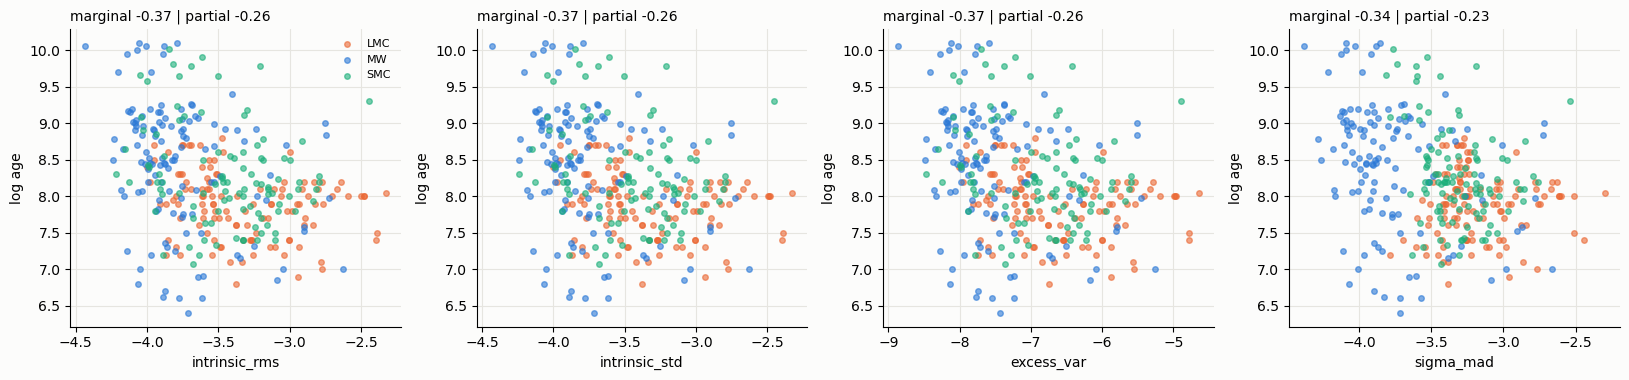

CONCLUSION —
  Raw relations for the strongest features. Colour shows that much of the apparent trend
  is galaxies sitting at different places; the residual version in the figure above is the
  one to read for the age relation itself.


In [73]:
# Scatter of the strongest surviving features, coloured by galaxy
show = top[:4]
fig, axs = plt.subplots(1, len(show), figsize=(4.1 * len(show), 3.9), squeeze=False)
colours = {'MW': '#2a78d6', 'LMC': '#eb6834', 'SMC': '#1baf7a'}
for ax, f in zip(axs[0], show):
    for o, g in clusters.groupby('origin'):
        ax.scatter(g[f], g.age, s=16, alpha=.6, color=colours.get(o, '#8f8e88'), label=o)
    r = out.set_index('feature').loc[f]
    ax.set(xlabel=f, ylabel='log age')
    ax.set_title(f'marginal {r.rho:+.2f} | partial {r.rho_partial:+.2f}', loc='left', fontsize=10)
axs[0][0].legend(fontsize=8)
plt.tight_layout(); plt.show()

print('CONCLUSION —')
print('  Raw relations for the strongest features. Colour shows that much of the apparent trend')
print('  is galaxies sitting at different places; the residual version in the figure above is the')
print('  one to read for the age relation itself.')


In [74]:
OUT = 'results_linear_correlations.csv'
out.to_csv(OUT, index=False)
print('wrote', OUT)
n_sig = int((out.p_partial_fdr < 0.05).sum())
print(f'{n_sig} of {len(out)} features keep a partial correlation with age at FDR < 0.05')
display(out[out.p_partial_fdr < 0.05][['feature', 'rho', 'rho_partial', 'p_partial_fdr', 'p_perm_fdr']].round(4))

wrote results_linear_correlations.csv
15 of 23 features keep a partial correlation with age at FDR < 0.05


,feature,rho,rho_partial,p_partial_fdr,p_perm_fdr
0,intrinsic_rms,-0.3715,-0.2562,0.0000,0.0029
1,intrinsic_std,-0.3714,-0.2557,0.0000,0.0029
2,excess_var,-0.3714,-0.2557,0.0000,0.0029
3,sigma_mad,-0.3392,-0.2289,0.0001,0.0029
13,rn_alpha,-0.0990,-0.2229,0.0002,0.9712
10,vn_ratio_gap_aware,-0.1448,-0.2126,0.0003,0.1128
15,stetson_j_gap_aware,-0.0477,-0.1977,0.0008,1.0000
4,gp_sigma_max,-0.3013,-0.1852,0.0032,0.0029
7,gp_n_components_filtered,-0.1629,-0.1789,0.0027,0.0029
11,LSP_peak_snr_rn,-0.1329,-0.1717,0.0035,0.0528


## 8 · How to read this

* **Marginal but not partial** → the correlation was the galaxy or the observing setup, not age.
* **Partial and within-origin agree in sign** → the strongest evidence available here.
* **Only one galaxy shows it** → suspect. The MW is the only subsample with a wide age range,
  so an MW-only signal is plausible but rests on ~124 clusters.
* **Nothing survives** → a real and publishable result for this pipeline: these statistics do
  not encode age at the precision reached, which bounds what the ML model in the next notebook
  can honestly achieve.

Two limits worth stating whatever happens. Ages come from the Wainer catalogue and carry their
own uncertainty, which dilutes every correlation here — none of this is corrected for that.
And the median over sector combinations discards genuine variation between epochs; a cluster
whose variability changes between sectors is represented by one number.